<a href="https://colab.research.google.com/github/SaharaAli16/UNT_Teaching/blob/main/DTSC_4050/Week_10_Hypothesis_Testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DTSC 4050 — Class Activity: Hypothesis Testing by Simulation

This activity follows the lecture's **25 coin flips → 21 heads** example.

### Goals
- Identify parameters and statistics
- Write null and alternative hypotheses
- Choose a test statistic
- Build a null distribution by simulation
- Calculate and interpret a p-value
- Make a decision using α
- Identify Type I and Type II errors


## 0. Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(4050)

# Part 1 — Parameter and Statistic

For a coin:
- **b** = true probability of heads (parameter)
- **b-hat = H/n** = sample proportion of heads (statistic)

## Activity 1
We flip a coin 25 times and observe 21 heads.

1. What is n?
2. What is H?
3. Calculate H/n.



In [ ]:
n = 25
heads = 21
b_hat = heads / n
print("Observed proportion of heads =", b_hat)

Observed proportion of heads = 0.84


## Activity 2 — Random samples vary

Run this cell several times. A fair coin does not have to produce exactly 12 or 13 heads every time.

In [ ]:
sample = rng.choice(["H", "T"], size=25, p=[0.5, 0.5])
print(sample)
print("Heads:", np.sum(sample == "H"))
print("Proportion heads:", np.mean(sample == "H"))

['H' 'T' 'H' 'H' 'H' 'H' 'T' 'H' 'T' 'T' 'H' 'H' 'T' 'H' 'H' 'T' 'H' 'H'
 'H' 'T' 'T' 'H' 'T' 'H' 'H']
Heads: 16
Proportion heads: 0.64


# Part 2 — Hypotheses

Research question: **Does this coin behave like a fair coin?**

## Activity 3
Let's write both hypotheses in words.

**H₀: the coin is fair**  

**Hₐ: the coin is not fair**

# Part 3 — Test Statistic

If the coin is fair, the expected number of heads is:

**25 × 0.5 = 12.5**

For the two-sided alternative, use:

**T = |Number of Heads − 12.5|**

Small T → more consistent with H₀  
Large T → more evidence toward Hₐ

## Activity 4
Calculate T for the observed 21 heads.

In [19]:
expected_heads = 25 * 0.5

# YOUR CODE
observed_T = 21 - expected_heads
observed_T = np.abs(observed_T)

print("Expected heads:", expected_heads)
print("Observed T:", observed_T)

Expected heads: 12.5
Observed T: 8.5


### Check your understanding

Let's calculate T for a different observation for number of Heads.

In [27]:
expected_heads = 25 * 0.5
observed_heads = 19
#observed_heads = 4
#observed_heads = 10

# YOUR CODE
observed_T = observed_heads - expected_heads
observed_T = np.abs(observed_T)

print("Expected heads:", expected_heads)
print("Observed T:", observed_T)

Expected heads: 12.5
Observed T: 6.5


# Part 4 — Simulate Under H₀


**Assume H₀ → generate sample → compute statistic → repeat → compare with observed result**

Simulate **1,000 experiments**, each with 25 flips of a fair coin.

In [28]:
n_simulations = 1000
simulated_heads = []

for i in range(n_simulations):
    flips = rng.choice([1, 0], size=25, p=[0.5, 0.5])
    simulated_heads.append(np.sum(flips))

simulated_heads = np.array(simulated_heads)
print(simulated_heads[:20])

[14 13 15 10 12 15 14 13 13 12 12 13 14 11 13 13 13 11 16  8]


## Visualize the Empirical Distribution of our Statistic

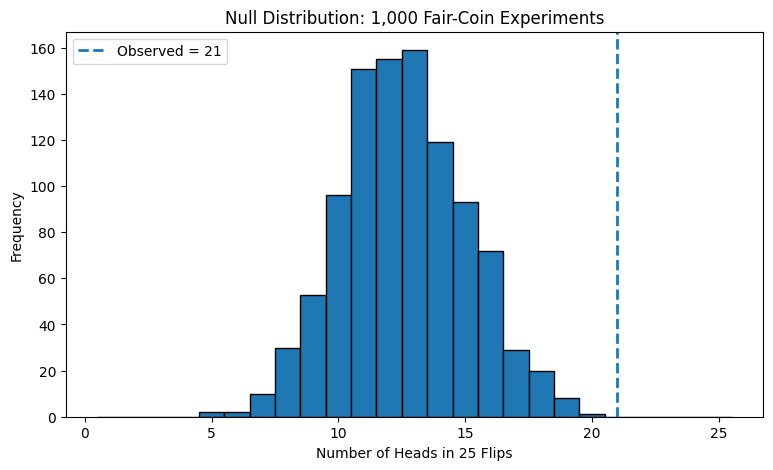

In [29]:
plt.figure(figsize=(9,5))
plt.hist(simulated_heads, bins=np.arange(0.5,26.5,1), edgecolor="black")
plt.axvline(21, linestyle="--", linewidth=2, label="Observed = 21")
plt.xlabel("Number of Heads in 25 Flips")
plt.ylabel("Frequency")
plt.title("Null Distribution: 1,000 Fair-Coin Experiments")
plt.legend()
plt.show()

### Let's interpret the graph
1. Where is the center?
2. Is 21 near the center or in an extreme region?
3. Does 21 look typical if H₀ is true?



# Part 5 — Simulate the Test Statistic

Now convert every simulated head count into:

**T = |H − 12.5|**

In [30]:
simulated_T = np.abs(simulated_heads - expected_heads)

print("Observed T =", observed_T)
print("First 20 simulated T values:")
print(simulated_T[:20])

Observed T = 6.5
First 20 simulated T values:
[1.5 0.5 2.5 2.5 0.5 2.5 1.5 0.5 0.5 0.5 0.5 0.5 1.5 1.5 0.5 0.5 0.5 1.5
 3.5 4.5]


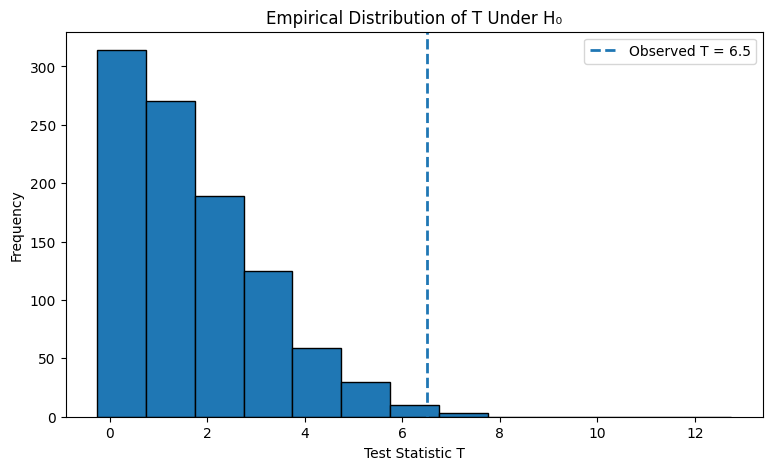

In [31]:
plt.figure(figsize=(9,5))
plt.hist(simulated_T, bins=np.arange(-0.25,13.25,1), edgecolor="black")
plt.axvline(observed_T, linestyle="--", linewidth=2, label=f"Observed T = {observed_T}")
plt.xlabel("Test Statistic T")
plt.ylabel("Frequency")
plt.title("Empirical Distribution of T Under H₀")
plt.legend()
plt.show()

## Activity 6
Is the observed T common or unusual under H₀? Explain using the graph.



# Part 6 — Calculate the p-Value

The **p-value** is the probability of obtaining a test statistic at least as extreme as the observed statistic, **assuming H₀ is true**.

Using simulation:

**p-value ≈ (# simulated T ≥ observed T) / (# simulations)**

In [32]:
# YOUR CODE
extreme = np.sum(simulated_T >= observed_T)
p_value = extreme / n_simulations

print("Extreme simulations:", extreme)
print("Simulated p-value:", p_value)

Extreme simulations: 13
Simulated p-value: 0.013


# Part 7 — Statistical Significance

Use **α = 0.05**.

- p < 0.05 → reject H₀
- p ≥ 0.05 → fail to reject H₀

## Activity 7
Predict the decision before running the cell.

**YOUR PREDICTION:**

In [33]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
else:
    print("Fail to reject H0")

Reject H0


### Conclusion
From this experiment, we conclude that the coin is not fair.

# Part 8 — Change the Observed Result

Suppose we observed **15 heads instead of 21**.

## Activity
Calculate its T and simulation-based p-value. Would the decision at α=.05 change?

In [40]:
new_heads = 15

# YOUR CODE
new_T = np.abs(new_heads - expected_heads)

heads_null = rng.binomial(n=25, p=0.5, size=10_000)
T_null = np.abs(heads_null - 12.5)

# YOUR CODE
new_p_value = np.sum(T_null >= new_T) / 10_000

print("New T:", new_T)
print("New p-value:", new_p_value)

New T: 2.5
New p-value: 0.4187


Since p-value > α, we fail to reject the null-hypothesis.

# Part 9 — Type I and Type II Errors

- **Type I:** reject a true H₀ (false positive)
- **Type II:** fail to reject a false H₀ (false negative)

## Activity 11

**A.** The coin is actually fair, but we conclude it is not fair.  
This is a Type ____ error because __________________________.

**B.** The coin is actually biased, but we fail to find sufficient evidence against H₀.  
This is a Type ____ error because __________________________.